In [1]:
import pandas as pd
df = pd.read_csv("04_logistic_customer_churn.csv")
df.head()

,Monthly_Bill,Tenure_Months,Support_Calls,Late_Payments,Monthly_Usage_Hours,Churn
0,27.92,34,2,1,63.53,0
1,153.33,46,3,2,55.53,0
2,155.03,4,6,3,62.56,1
3,65.59,30,5,0,28.06,0
4,94.06,72,2,2,41.90,0


In [2]:
x=df.drop(columns=['Churn'])
y=df['Churn']

In [3]:
from sklearn.model_selection import train_test_split 

X_train, X_test, Y_train, Y_test = train_test_split(x, y, train_size=0.8, random_state=42)

In [4]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, roc_auc_score

y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]  # churn probabilities, used for the ROC curve below
print(f"Accuracy Score: {accuracy_score(Y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(Y_test, y_pred))


Accuracy Score: 72.00%

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.89      0.82        36
           1       0.50      0.29      0.36        14

    accuracy                           0.72        50
   macro avg       0.63      0.59      0.59        50
weighted avg       0.69      0.72      0.69        50



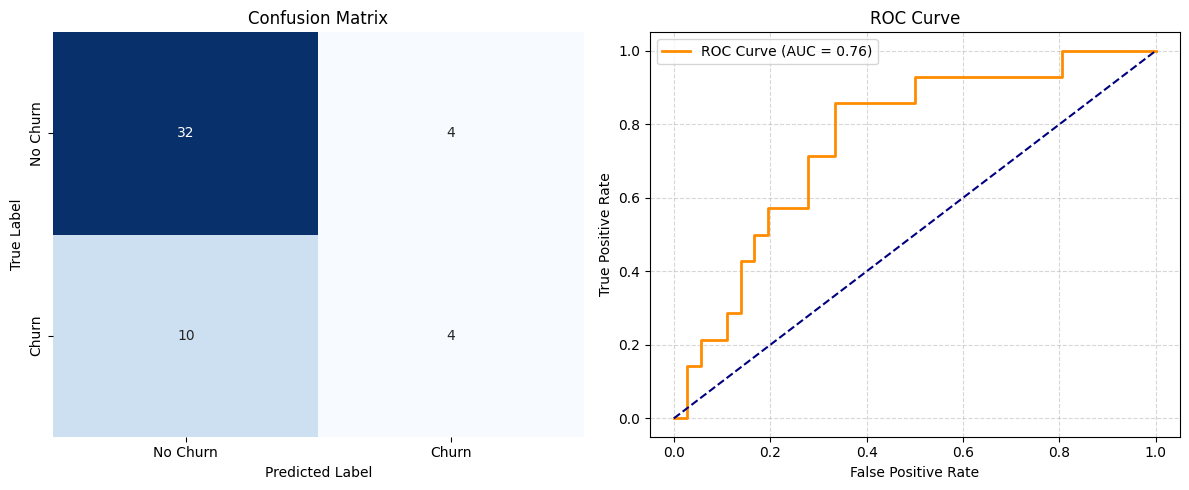

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
cm = confusion_matrix(Y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

plt.subplot(1, 2, 2)
fpr, tpr, _ = roc_curve(Y_test, y_proba)
auc_score = roc_auc_score(Y_test, y_proba)

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [8]:
sample_customer = pd.DataFrame([{
    'Monthly_Bill': 120.50,
    'Tenure_Months': 3,
    'Support_Calls': 5,
    'Late_Payments': 2,
    'Monthly_Usage_Hours': 15.0
}])

sample_scaled = scaler.transform(sample_customer)
prediction = model.predict(sample_scaled)[0]
probability = model.predict_proba(sample_scaled)[0][1]

print(f"\nPrediction Result: {'Churn' if prediction == 1 else 'No Churn'}")
print(f"Churn Probability: {probability * 100:.2f}%")


Prediction Result: Churn
Churn Probability: 82.34%
